# Predicting Benzene Concentration from Low-Cost Gas Sensors

**Project type:** Supervised regression  
**Dataset:** UCI Air Quality  
**Target:** `C6H6(GT)` — reference-analyser benzene concentration  
**Objective:** Estimate benzene concentration using low-cost sensor readings and meteorological variables.

## Project workflow

1. Load and inspect the raw data.
2. Clean invalid and missing values.
3. Explore the target, features, and time patterns.
4. Define a chronological train/test split.
5. Establish a dummy baseline.
6. Train and compare regression models using preprocessing pipelines.
7. Inspect errors, feature importance, and a feature-ablation experiment.
8. Record limitations and next steps.

> **Important scope note:** This notebook is an exploratory modelling experiment. It is structured for reproducibility, but it is not yet a production deployment. The next engineering step is to move reusable logic into Python modules, add automated tests, and create a repeatable training/inference pipeline.

## 1. Environment setup and imports

Keep imports, configuration, and project paths together near the beginning. This makes dependencies visible and avoids importing the same library in multiple sections.

In [33]:
# Standard library
from pathlib import Path

# Third-party libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: preprocessing, models, and evaluation
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reproducibility and display configuration
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

### Project paths

Expected project layout:

```text
ml-demos/
│
├── data/
│   └── air+quality/
│       ├── raw/
│       │   └── AirQualityUCI.csv
│       │
│       └── cleaned/
│
└── notebooks/
    └── air_quality_benzene.ipynb
```

Place the original UCI CSV in `data/raw/`. The path logic below also recognizes the existing `data/air+quality/raw/` layout and supports running the notebook from the project root or its `notebooks/` directory. Avoid machine-specific absolute paths.

In [34]:
# Define the current working directory
CURRENT_DIR = Path.cwd()

# Navigate to the project root directory
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

# Define the path to the raw data file
RAW_DATA_PATH = PROJECT_ROOT/"data"/"air_quality"/"raw"/"AirQualityUCI.csv"

# Cleaned data path
CLEANED_DATA_PATH = PROJECT_ROOT/"data"/"air_quality"/"cleaned"

# Create the cleaned data directory if it doesn't exist
CLEANED_DATA_PATH.mkdir(parents=True, exist_ok=True)

# Validate input path
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Raw data file not found at {RAW_DATA_PATH}. Please ensure the dataset is downloaded and placed in the correct directory.")

print("Current working directory:", CURRENT_DIR)
print("Project root directory:", PROJECT_ROOT)
print("Raw data path:", RAW_DATA_PATH)
print("Cleaned data path:", CLEANED_DATA_PATH)

Current working directory: d:\ml-demos\notebooks
Project root directory: d:\ml-demos
Raw data path: d:\ml-demos\data\air_quality\raw\AirQualityUCI.csv
Cleaned data path: d:\ml-demos\data\air_quality\cleaned


## 2. Load and inspect the data

The source file uses semicolons as field separators and commas as decimal separators.

In [35]:
aq_raw = pd.read_csv(RAW_DATA_PATH, sep=";", decimal=",")

print(f"Raw shape: {aq_raw.shape}")
display(aq_raw)
display(aq_raw.dtypes.to_frame("data_type"))

Raw shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,data_type
Date,str
Time,str
CO(GT),float64
PT08.S1(CO),float64
NMHC(GT),float64
C6H6(GT),float64
PT08.S2(NMHC),float64
NOx(GT),float64
PT08.S3(NOx),float64
NO2(GT),float64


In [36]:
# Inspect fully empty rows and columns before removing them.
fully_empty_rows = aq_raw.isna().all(axis=1).sum()
fully_empty_columns = aq_raw.columns[aq_raw.isna().all(axis=0)].tolist()

print(f"Fully empty rows: {fully_empty_rows}")
print(f"Fully empty columns: {fully_empty_columns}")

Fully empty rows: 114
Fully empty columns: ['Unnamed: 15', 'Unnamed: 16']


## 3. Data cleaning and timestamp preparation

The dataset uses `-200` as a marker for missing measurements. Converting this marker to `NaN` before calculating missing-value statistics or training models is required.

Removal of rows and columns that are entirely empty. The `NMHC(GT)` reference-analyser column has extensive missingness and is not part of the selected feature set, so it is excluded from this experiment.

Rows with a missing target cannot be used for supervised training or evaluation. Missing feature values are retained for now and will be imputed inside model pipelines.

In [37]:
aq = aq_raw.copy()

# Convert the dataset's missing-value markers to NaN.
aq = aq.replace(-200, np.nan)

# Remove completely empty rows and columns.
aq = aq.dropna(axis=0, how="all")
aq = aq.dropna(axis=1, how="all")
display(aq.describe())
display((aq.isnull().mean()*100).round(2).sort_values(ascending=False).to_frame("missing_percentage"))

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,7674.000000,8991.000000,914.000000,8991.000000,8991.000000,7718.000000,8991.000000,7715.000000,8991.000000,8991.000000,8991.000000,8991.000000,8991.000000
mean,2.152750,1099.833166,218.811816,10.083105,939.153376,246.896735,835.493605,113.091251,1456.264598,1022.906128,18.317829,49.234201,1.025530
std,1.453252,217.080037,204.459921,7.449820,266.831429,212.979168,256.817320,48.370108,346.206794,398.484288,8.832116,17.316892,0.403813
min,0.100000,647.000000,7.000000,0.100000,383.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700
25%,1.100000,937.000000,67.000000,4.400000,734.500000,98.000000,658.000000,78.000000,1227.000000,731.500000,11.800000,35.800000,0.736800
50%,1.800000,1063.000000,150.000000,8.200000,909.000000,180.000000,806.000000,109.000000,1463.000000,963.000000,17.800000,49.600000,0.995400
75%,2.900000,1231.000000,297.000000,14.000000,1116.000000,326.000000,969.500000,142.000000,1674.000000,1273.500000,24.400000,62.500000,1.313700
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


,missing_percentage
NMHC(GT),90.23
CO(GT),17.99
NO2(GT),17.55
NOx(GT),17.52
PT08.S2(NMHC),3.91
C6H6(GT),3.91
PT08.S1(CO),3.91
PT08.S5(O3),3.91
T,3.91
PT08.S3(NOx),3.91


In [38]:
# This reference-analyser column is missing 90 percent of values, it will not be used in the selected modelling task.
aq = aq.drop(columns=["NMHC(GT)"])

print(f"Shape after removing fully empty rows/columns and NMHC(GT): {aq.shape}")
display(aq.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

Shape after removing fully empty rows/columns and NMHC(GT): (9357, 14)


,missing_values
CO(GT),1683
NO2(GT),1642
NOx(GT),1639
PT08.S2(NMHC),366
C6H6(GT),366
PT08.S1(CO),366
PT08.S5(O3),366
T,366
PT08.S3(NOx),366
PT08.S4(NO2),366


In [39]:
# Remove rows where the supervised target is unavailable.
target = "C6H6(GT)"
missing_target_count = aq[target].isna().sum()

aq = aq.dropna(subset=[target]).copy()

print(f"Rows removed because target was missing values: {missing_target_count}")
print(f"Rows available after target filtering: {len(aq)}")

Rows removed because target was missing values: 366
Rows available after target filtering: 8991


### Convert `Date` and `Time` into a timestamp

A chronological split requires correctly ordered observations. Combine the two source columns into a pandas datetime index, remove the original text columns, and sort explicitly.

In [40]:
timestamp = pd.to_datetime(
    aq["Date"] + " " + aq["Time"],
    format="%d/%m/%Y %H.%M.%S",
    errors="raise"
)

aq = aq.drop(columns=["Date", "Time"])
aq.index = timestamp
aq.index.name = "Timestamp"
aq = aq.sort_index()

print(f"Date range: {aq.index.min()} to {aq.index.max()}")
print(f"Duplicate timestamps: {aq.index.duplicated().sum()}")

Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Duplicate timestamps: 0


In [41]:
# Inspect sampling intervals and gaps.
time_gaps = aq.index.to_series().diff()

display(time_gaps.value_counts().head(10).to_frame("interval_count"))
print(f"Largest gap: {time_gaps.max()}")

,interval_count
Timestamp,
0 days 01:00:00,8974
0 days 02:00:00,3
0 days 04:00:00,1
1 days 01:00:00,1
0 days 15:00:00,1
1 days 15:00:00,1
0 days 05:00:00,1
1 days 22:00:00,1
0 days 11:00:00,1


Largest gap: 3 days 05:00:00


**Interpretation:** Most observations are hourly, but there are some gaps. A row-wise model can still be trained on the available observations, but gaps matter for lag-based features, rolling windows, and time-series validation. Those approaches would need explicit handling of missing time intervals.

## 4. Exploratory data analysis

EDA helps understand the target distribution, missingness, time patterns, and relationships between the features or the candidate predictors and the target. These observations help in modelling choices.

In [42]:
display(aq.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
CO(GT),7344.0,2.13,1.44,0.10,1.10,1.8,2.80,11.90
PT08.S1(CO),8991.0,1099.83,217.08,647.00,937.00,1063.0,1231.00,2040.00
C6H6(GT),8991.0,10.08,7.45,0.10,4.40,8.2,14.00,63.70
PT08.S2(NMHC),8991.0,939.15,266.83,383.00,734.50,909.0,1116.00,2214.00
NOx(GT),7396.0,242.19,206.31,2.00,97.00,178.0,321.00,1479.00
PT08.S3(NOx),8991.0,835.49,256.82,322.00,658.00,806.0,969.50,2683.00
NO2(GT),7393.0,112.15,47.63,2.00,77.00,109.0,140.00,333.00
PT08.S4(NO2),8991.0,1456.26,346.21,551.00,1227.00,1463.0,1674.00,2775.00
PT08.S5(O3),8991.0,1022.91,398.48,221.00,731.50,963.0,1273.50,2523.00
T,8991.0,18.32,8.83,-1.90,11.80,17.8,24.40,44.60


### Missingness after target filtering

In [43]:
missing_summary = pd.DataFrame({
    "missing_count": aq.isna().sum(),
    "missing_percent": (aq.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

,missing_count,missing_percent
CO(GT),1647,18.32
NO2(GT),1598,17.77
NOx(GT),1595,17.74
PT08.S1(CO),0,0.00
PT08.S2(NMHC),0,0.00
C6H6(GT),0,0.00
PT08.S3(NOx),0,0.00
PT08.S4(NO2),0,0.00
PT08.S5(O3),0,0.00
T,0,0.00


### Target distribution

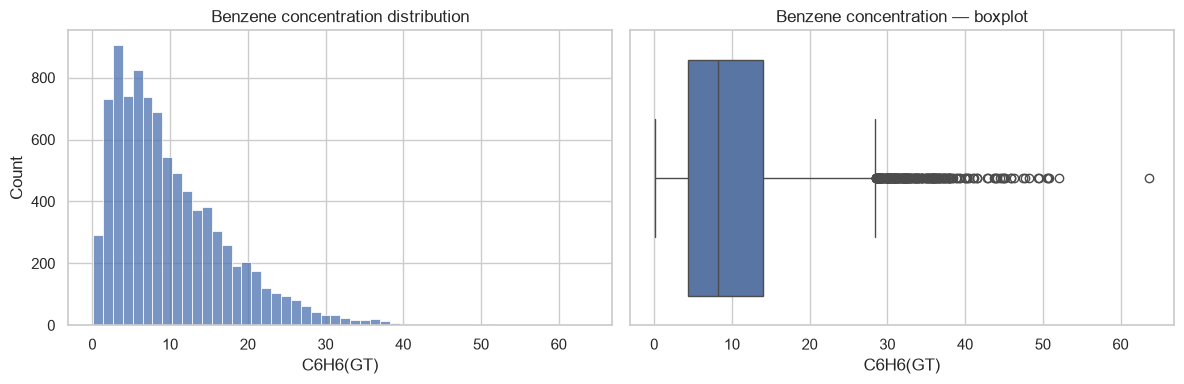

Skew:   1.36
Mean:   10.08
Median: 8.20
Range:  0.10 to 63.70


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(aq[target], bins=50, ax=axes[0])
axes[0].set_title("Benzene concentration distribution")
axes[0].set_xlabel("C6H6(GT)")

sns.boxplot(x=aq[target], ax=axes[1])
axes[1].set_title("Benzene concentration — boxplot")
axes[1].set_xlabel("C6H6(GT)")

plt.tight_layout()
plt.show()

print(f"Skew:   {aq[target].skew():.2f}")
print(f"Mean:   {aq[target].mean():.2f}")
print(f"Median: {aq[target].median():.2f}")
print(f"Range:  {aq[target].min():.2f} to {aq[target].max():.2f}")

### Feature distributions

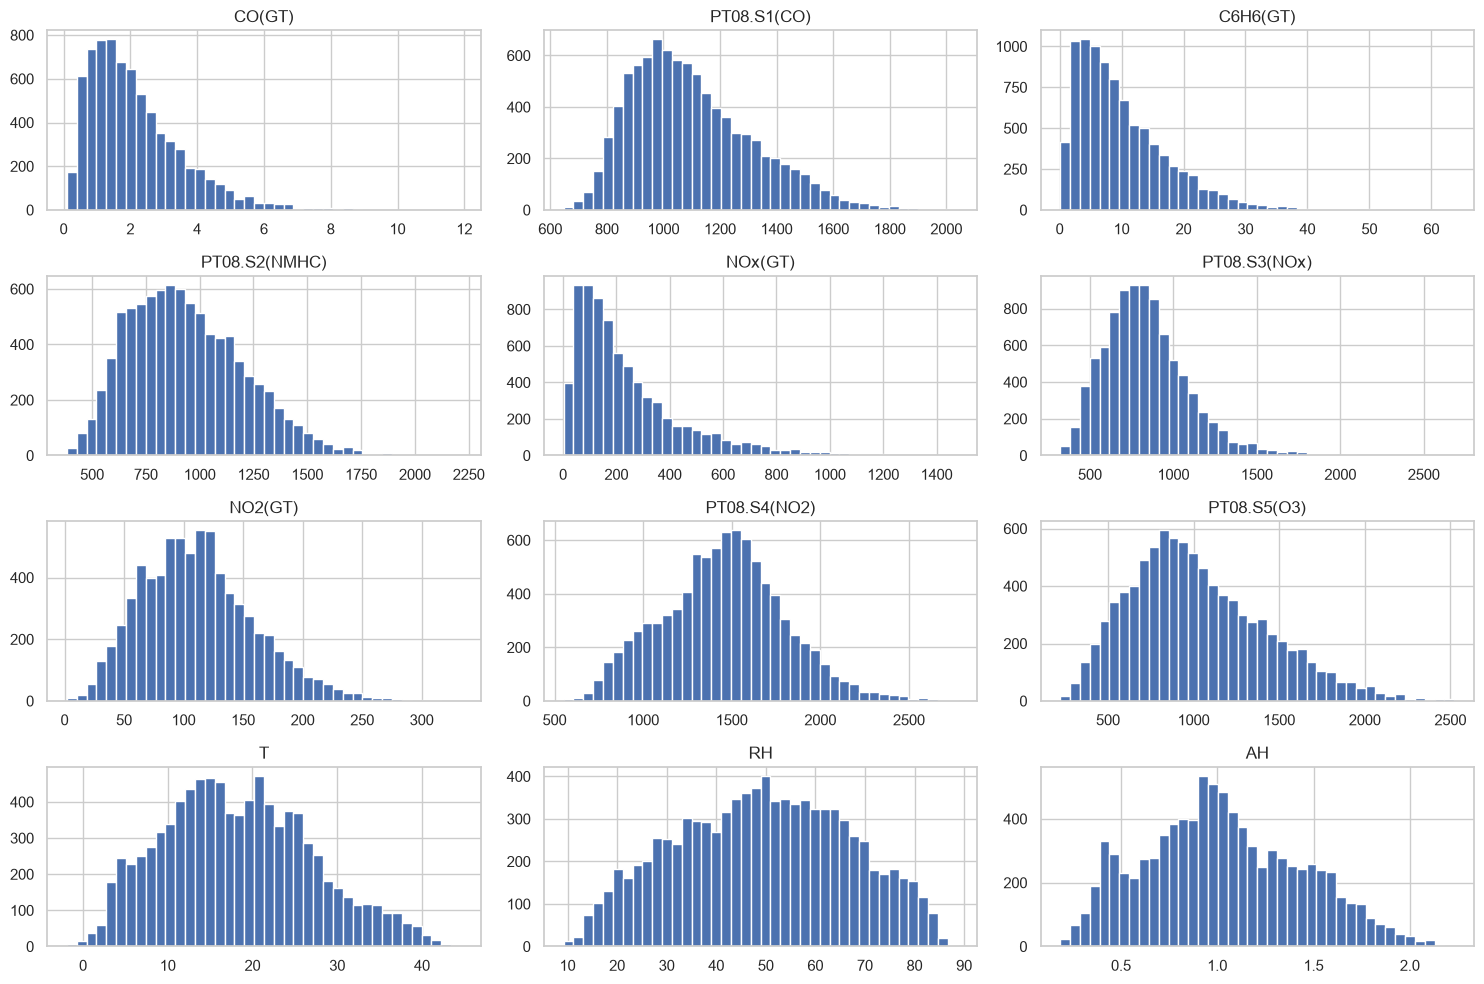

In [46]:
aq.hist(bins=40, figsize=(15, 10))
plt.tight_layout()
plt.show()

### Target over time

Since the dataset contains around 9000 hourly points, it would be easier to analyse the Benzene distribution on a day basis.

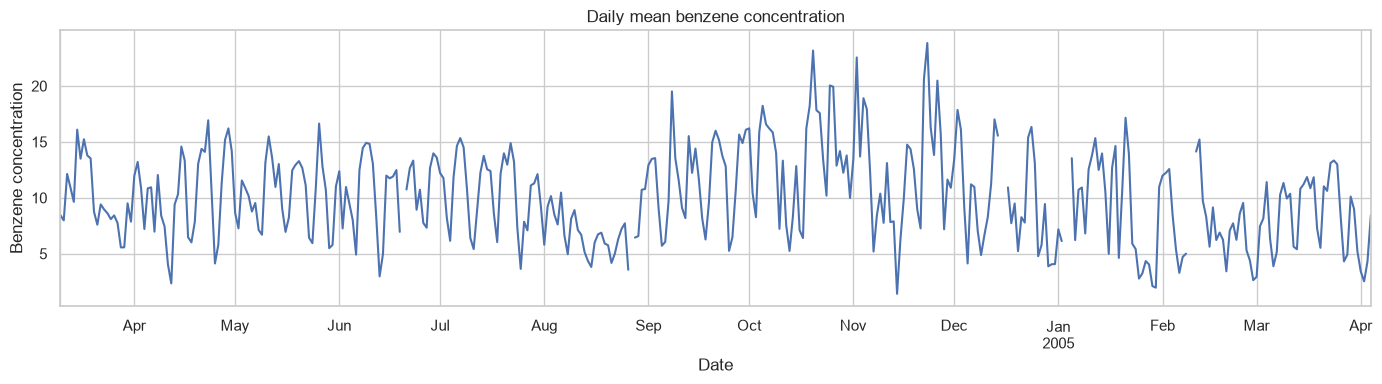

In [47]:
daily_target = aq[target].resample("D").mean()

ax = daily_target.plot(figsize=(14, 4), title="Daily mean benzene concentration")
ax.set_ylabel("Benzene concentration")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()

### Average target by hour of day

Distribution of hourly Benzene concentration averaged across all the days in the dataset.

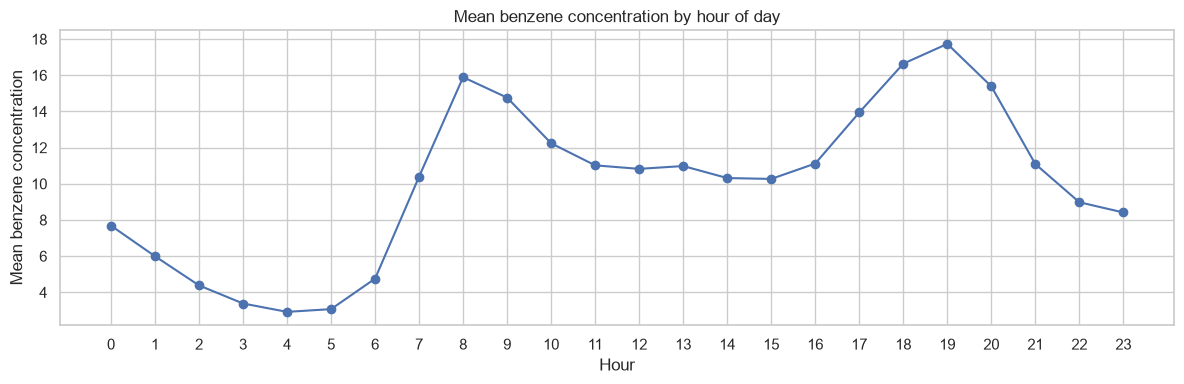

In [55]:
hourly_target = aq.groupby(aq.index.hour)[target].mean()

ax = hourly_target.plot(figsize=(12, 4), marker="o")
ax.set_title("Mean benzene concentration by hour of day")
ax.set_xlabel("Hour")
ax.set_ylabel("Mean benzene concentration")
ax.set_xticks(range(24))
plt.tight_layout()
plt.show()

## 5. Define the modelling problem

The objective is to estimate reference-analyser benzene concentration from the five low-cost sensor channels and three meteorological variables.

The columns ending in `(GT)` are reference-analyser measurements. They are excluded from the predictors to avoid using other reference-analyser readings as inputs to a low-cost-sensor model.

In [56]:
features = [
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH",
]

target = "C6H6(GT)"

X = aq[features].copy()
Y = aq[target].copy()

print(f"Number of observations: {len(X)}")
print(f"Number of features: {len(features)}")
print(f"Target: {target}")
print(f"Missing feature values: {X.isna().sum().sum()}")

Number of observations: 8991
Number of features: 8
Target: C6H6(GT)
Missing feature values: 0


### Feature-target relationships

Correlation and scatter plots can reveal strong associations, nonlinear patterns, and possible explanations about model performance.

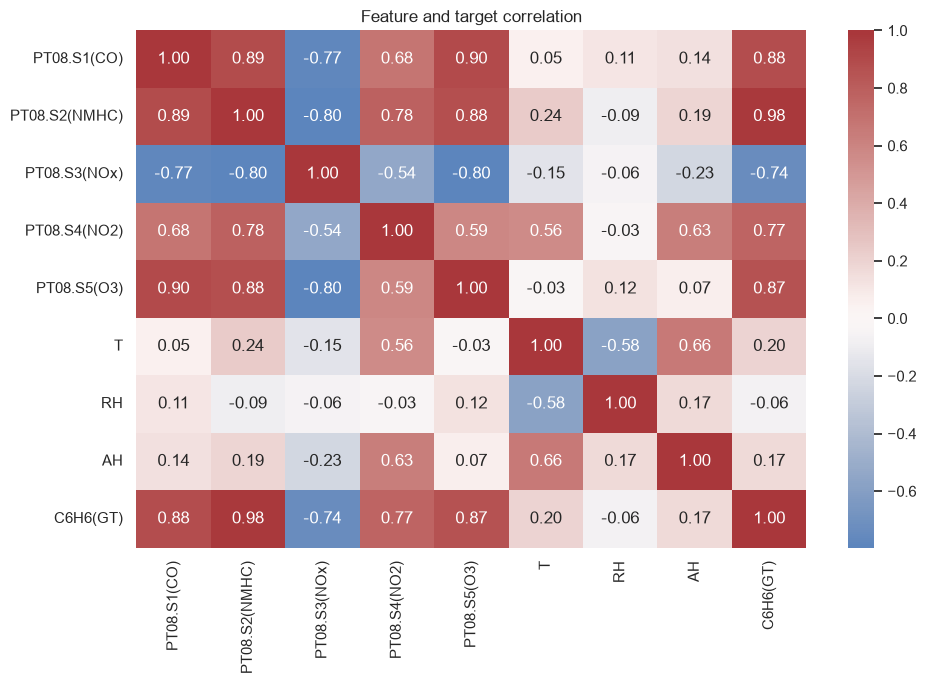

,correlation_with_target
PT08.S2(NMHC),0.981950
PT08.S1(CO),0.883795
PT08.S5(O3),0.865689
PT08.S4(NO2),0.765731
T,0.198956
AH,0.167972
RH,-0.061681
PT08.S3(NOx),-0.735744


In [57]:
correlation = aq[features + [target]].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Feature and target correlation")
plt.tight_layout()
plt.show()

display(correlation[target].drop(target).sort_values(ascending=False).to_frame("correlation_with_target"))

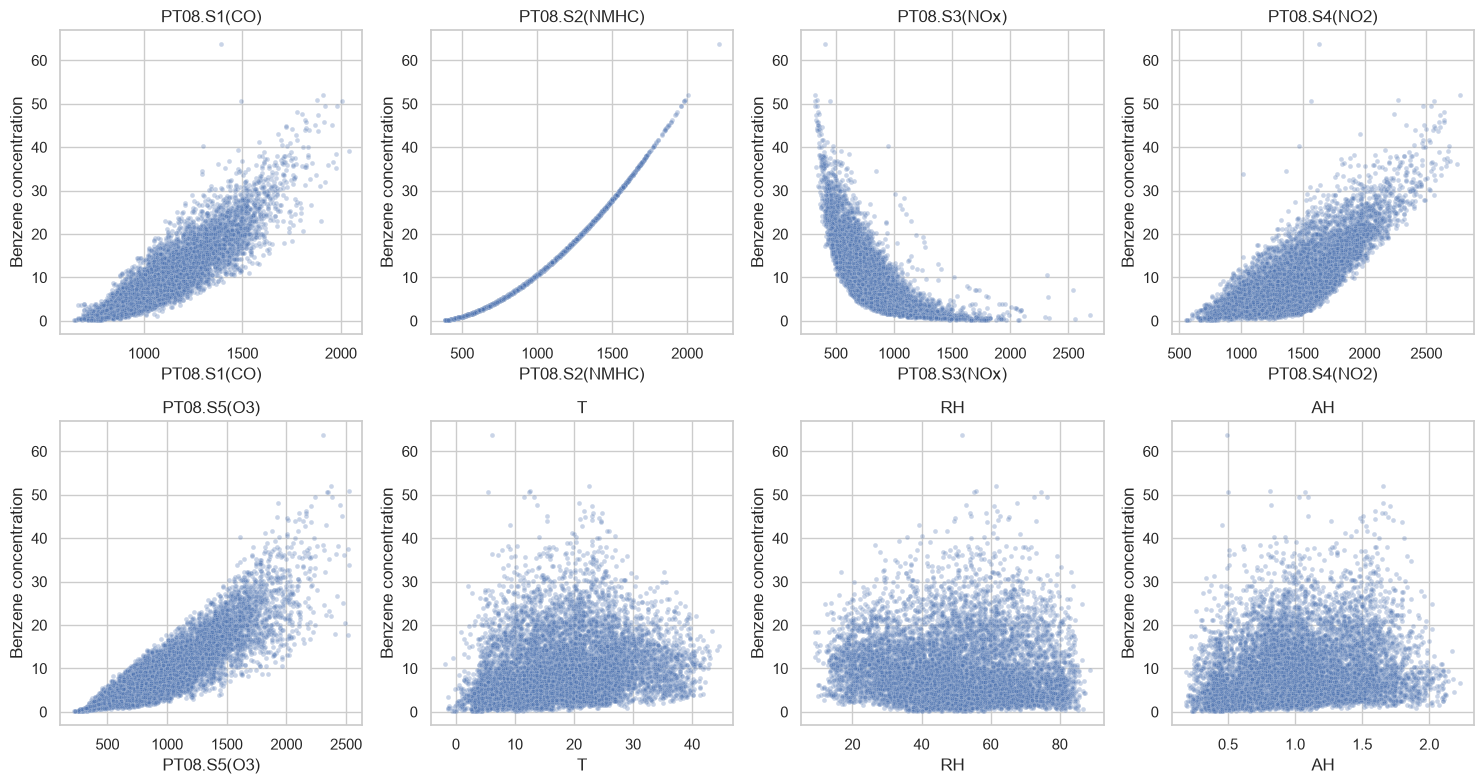

In [58]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for feature, ax in zip(features, axes.flat):
    sns.scatterplot(data=aq, x=feature, y=target, s=12, alpha=0.3, ax=ax)
    ax.set_title(feature)
    ax.set_ylabel("Benzene concentration")

plt.tight_layout()
plt.show()

## 6. Chronological train/test split

The intended use is to predict observations occurring after the data used for training. Therefore, split chronologically rather than randomly.

A random split might put very similar observations in both the training and test sets. Splitting the data by time gives a more realistic first test of how well the model predicts future data. However, it uses only one time period, so it cannot show how well the model performs in other years or locations.


In [60]:
split_position = int(len(X) * 0.80)

X_train = X.iloc[:split_position].copy()
X_test = X.iloc[split_position:].copy()
Y_train = Y.iloc[:split_position].copy()
Y_test = Y.iloc[split_position:].copy()

print(
    f"Train period: {X_train.index.min()} to {X_train.index.max()} "
    f"({len(X_train):,} rows)"
)
print(
    f"Test period:  {X_test.index.min()} to {X_test.index.max()} "
    f"({len(X_test):,} rows)"
)
print(f"Training shape: {X_train.shape}; target shape: {Y_train.shape}")
print(f"Test shape:     {X_test.shape}; target shape: {Y_test.shape}")

Train period: 2004-03-10 18:00:00 to 2005-01-16 01:00:00 (7,192 rows)
Test period:  2005-01-16 02:00:00 to 2005-04-04 14:00:00 (1,799 rows)
Training shape: (7192, 8); target shape: (7192,)
Test shape:     (1799, 8); target shape: (1799,)


## 7. Establish a dummy baseline

A dummy regressor ignores the input features and predicts a simple statistic from the training target. Any useful model should improve on this baseline under the same test split and metrics.

The baseline helps interpret the model scores and can reveal problems with feature alignment or evaluation.

In [76]:
def regression_metrics(Y_true, Y_pred):
    """Return a consistent set of regression metrics."""
    return {
        "MAE": mean_absolute_error(Y_true, Y_pred),
        "RMSE": mean_squared_error(Y_true, Y_pred) ** 0.5,
        "R2": r2_score(Y_true, Y_pred),
    }

baseline_rows = {}

for strategy in ("mean", "median"):
    baseline = DummyRegressor(strategy=strategy)
    baseline.fit(X_train, Y_train)
    baseline_predictions = baseline.predict(X_test)
    baseline_rows[f"Dummy ({strategy})"] = regression_metrics(Y_test, baseline_predictions)

baseline_results = pd.DataFrame(baseline_rows).T
display(baseline_results.round(3))

,MAE,RMSE,R2
Dummy (mean),6.066,7.083,-0.182
Dummy (median),5.295,6.582,-0.021


## 8. Train and compare regression models

Use scikit-learn pipelines to keep preprocessing attached to each model. `SimpleImputer` learns column medians from the training data during `.fit()` and applies those same values to later data during `.predict()`.

This prevents the test set from influencing the imputation statistics and makes the preprocessing reusable at inference time.

However, after dropping the redundant features, empty rows and columns, and removing empty target rows, there are no missing values left in the training set.

In [71]:
model_pipelines = {
    "Linear regression": make_pipeline(
        SimpleImputer(strategy="median"),
        LinearRegression()
    ),
    "Decision tree (depth 6)": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE)
    ),
    "Random forest (200 trees)": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ),
    "Histogram gradient boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingRegressor(random_state=RANDOM_STATE)
    ),
}

In [74]:
model_predictions = {}
model_results = {}

for model_name, pipeline in model_pipelines.items():
    pipeline.fit(X_train, Y_train)
    predictions = pipeline.predict(X_test)

    model_predictions[model_name] = predictions
    model_results[model_name] = regression_metrics(Y_test, predictions)

model_results_df = pd.DataFrame(model_results).T.sort_values("MAE")
display(model_results_df.round(3))

,MAE,RMSE,R2
Random forest (200 trees),0.013,0.076,1.000
Histogram gradient boosting,0.059,0.218,0.999
Decision tree (depth 6),0.125,0.158,0.999
Linear regression,1.280,1.685,0.933


### Compare models with the dummy baseline

Review MAE, RMSE, and R² together. MAE and RMSE are in the target's units; RMSE penalizes large errors more strongly. R² measures performance relative to predicting the test-set mean and can be negative.

In [77]:
all_results = pd.concat([baseline_results, model_results_df])
display(all_results.round(3))

,MAE,RMSE,R2
Dummy (mean),6.066,7.083,-0.182
Dummy (median),5.295,6.582,-0.021
Random forest (200 trees),0.013,0.076,1.000
Histogram gradient boosting,0.059,0.218,0.999
Decision tree (depth 6),0.125,0.158,0.999
Linear regression,1.280,1.685,0.933


## 9. Error analysis

A single metric does not show where a model performs poorly. Inspect residuals and predicted-versus-observed values for the leading model. This helps identify systematic bias, extreme errors, and regions where performance deteriorates.

Lowest test MAE in this comparison: Random forest (200 trees)
MAE:  0.013
RMSE: 0.076
R²:   1.000


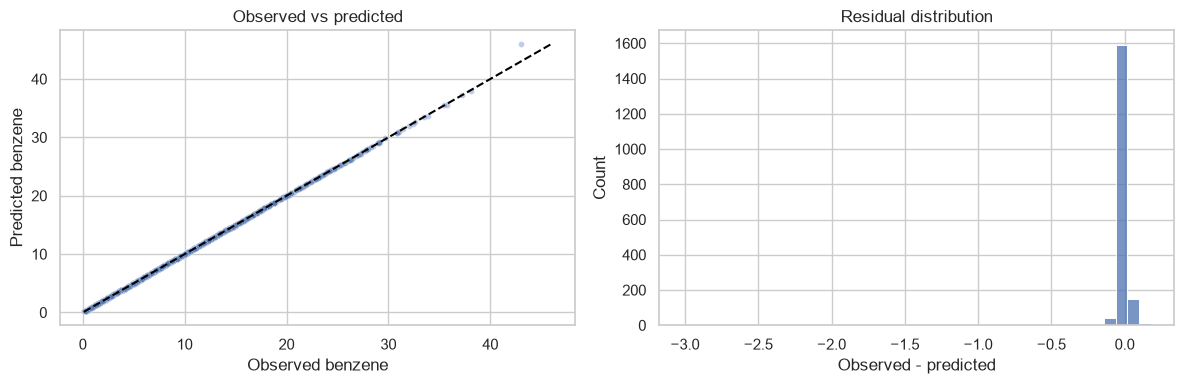

In [78]:
best_model_name = model_results_df["MAE"].idxmin()
best_predictions = model_predictions[best_model_name]
residuals = Y_test - best_predictions

print(f"Lowest test MAE in this comparison: {best_model_name}")
print(f"MAE:  {model_results[best_model_name]['MAE']:.3f}")
print(f"RMSE: {model_results[best_model_name]['RMSE']:.3f}")
print(f"R²:   {model_results[best_model_name]['R2']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(x=Y_test, y=best_predictions, alpha=0.35, s=18, ax=axes[0])
limits = [
    min(Y_test.min(), best_predictions.min()),
    max(Y_test.max(), best_predictions.max())
]
axes[0].plot(limits, limits, "--", color="black")
axes[0].set_title("Observed vs predicted")
axes[0].set_xlabel("Observed benzene")
axes[0].set_ylabel("Predicted benzene")

sns.histplot(residuals, bins=40, ax=axes[1])
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Observed - predicted")

plt.tight_layout()
plt.show()

## 10. Inspect feature importance and test the dominant-feature hypothesis

Tree-based feature importance can indicate which variables the fitted model used most heavily. It should not be interpreted as causal importance.

The original exploratory analysis suggested that `PT08.S2(NMHC)` is unusually strongly associated with benzene.

,importance
PT08.S2(NMHC),0.9996
AH,0.0001
PT08.S1(CO),0.0001
PT08.S3(NOx),0.0001
PT08.S4(NO2),0.0001
T,0.0001
PT08.S5(O3),0.0000
RH,0.0000


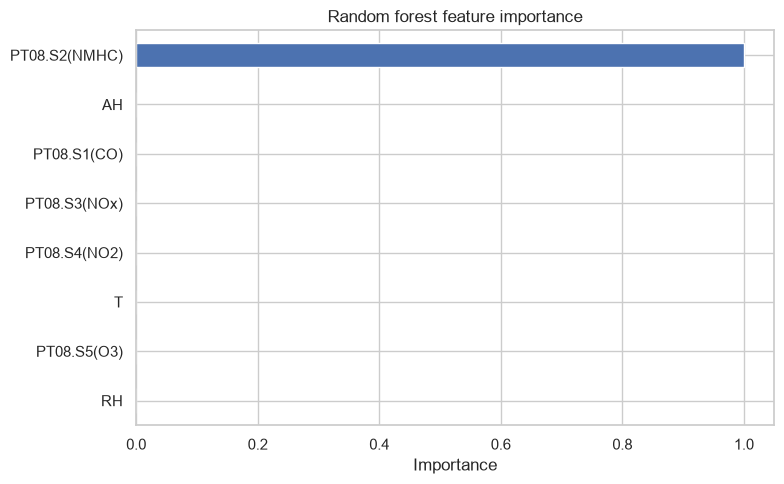

In [82]:
fitted_random_forest = model_pipelines["Random forest (200 trees)"].named_steps[
    "randomforestregressor"
]

feature_importance = pd.Series(
    fitted_random_forest.feature_importances_,
    index=features,
    name="importance"
).sort_values(ascending=False)

display(feature_importance.to_frame().round(4))

ax = feature_importance.sort_values().plot(kind="barh", figsize=(8, 5))
ax.set_title("Random forest feature importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

In [83]:
dominant_feature = "PT08.S2(NMHC)"
feature_sets = {
    "S2 only": [dominant_feature],
    "All except S2": [f for f in features if f != dominant_feature],
}

ablation_results = {}

for experiment_name, selected_features in feature_sets.items():
    experiment_pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingRegressor(random_state=RANDOM_STATE)
    )
    experiment_pipeline.fit(X_train[selected_features], Y_train)
    experiment_predictions = experiment_pipeline.predict(X_test[selected_features])
    ablation_results[experiment_name] = regression_metrics(Y_test, experiment_predictions)

ablation_results_df = pd.DataFrame(ablation_results).T
display(ablation_results_df.round(3))

,MAE,RMSE,R2
S2 only,0.041,0.106,1.000
All except S2,1.738,2.282,0.877


## 11. Findings, limitations, and next experiments

Complete this section after running the notebook from top to bottom. Base the statements on the newly generated outputs rather than copying old metric values.

### Findings
- Record the best-performing model on the chronological holdout.
- Compare it with the dummy baseline.
- Describe the strongest feature relationships.
- Summarize residual patterns and the feature-ablation result.

### Limitations
- The holdout is one later time period from one monitoring location.
- The test period may have a different target distribution from the training period.
- A strong association with one sensor may make this particular target unusually easy.
- No independent site or year has been used for external validation.
- This notebook does not yet include automated retraining, model serving, or production monitoring.

### Next experiments
1. Evaluate a more challenging target, such as `CO(GT)`, while handling its missing target values appropriately.
2. Use rolling or expanding-window validation to test stability across multiple time periods.
3. Investigate performance with and without the strongest sensor.
4. Add automated tests for data schema, missingness, chronological ordering, and prediction output.
5. Move reusable code into `src/` modules and create a reproducible training entry point.

## 12. Reproducibility checklist

Before sharing or using this notebook as a portfolio artifact:

- [ ] Run all cells from a fresh kernel in order.
- [ ] Confirm the raw dataset path works from the documented project layout.
- [ ] Confirm no machine-specific absolute paths remain.
- [ ] Confirm preprocessing is fitted only on training data.
- [ ] Regenerate all tables and plots.
- [ ] Update the findings section from the fresh results.
- [ ] Record package versions in a project requirements file.
- [ ] Keep raw data separate from generated/processed data.
- [ ] Save the notebook and code in version control.

**Next engineering milestone:** Extract data loading, preprocessing, training, and evaluation into importable Python modules; add `pytest` tests; then make training reproducible from a command-line entry point. That is the transition from notebook experimentation toward a maintainable ML project.